# 215. Kth Largest Element in an Array
**Difficulty:** 🟡 Medium · **Topic:** Heap · **Pattern:** [Top K](README.md) · **LeetCode:** https://leetcode.com/problems/kth-largest-element-in-an-array/

## 💡 Concepts

**Core concept(s):** **Top K with a size-k min-heap**, and its classic rival **Quickselect**.

**Why they apply here:**
- We need one value: the one that would sit at position `k` from the top if the array were sorted. Sorting everything does more work than that.
- **Heap:** keep only the `k` largest values; the smallest of them is the answer. `O(n log k)`.
- **Quickselect:** partition around a pivot like quicksort, but only keep going into the side that holds the answer. `O(n)` on average.

**Key intuition:**
- The k-th largest is the value at index `n - k` of the sorted array.
- A heap gets there by *discarding* everything below the top `k`.
- Quickselect gets there by *placing* one pivot at its final sorted index each round and throwing away the half that cannot contain index `n - k`.

---

### 📚 What is a Heap / Priority Queue?
- A **priority queue** is a bag of items where you can always take out the "most important" one next — here, the smallest.
- A **binary heap** is how it is built: a complete binary tree stored in a plain list, where every parent is `<=` its children (a **min-heap**).
- So the smallest item is always at index `0`; you can *peek* at it in **O(1)**.
- `push` adds at the end and bubbles the item up; `pop` removes the root, moves the last item to the top and sifts it down. Both are **O(log size)** because the tree is only `log size` levels tall.
- `heapify(list)` turns any list into a heap in **O(n)**.
- **In Python:** the `heapq` module works on a plain `list`: `heappush`, `heappop`, `heapify`, `heap[0]` to peek. It is a **min-heap only** — for a max-heap, push negated keys (`-x`).
- Tuples compare item by item, so `heappush(h, (priority, payload))` orders by `priority` first.

### 📚 What is the Top-K (size-k heap) technique?
- To keep the **k largest** values seen so far, keep them in a **min-heap capped at size k**.
- The root is the *smallest of the k largest* — the **k-th largest** overall. It is the "bouncer at the door".
- Each new value is pushed; if the heap grows to `k + 1`, pop the root. The value that leaves is the one that can no longer be in the top k.
- Each step is **O(log k)**, so `n` values cost **O(n log k)** time and only **O(k)** memory, instead of sorting all `n`.
- The direction is the counter-intuitive part: **k largest → min-heap**, **k smallest → max-heap** (the root is always the one to evict next).

### 📚 What is Quickselect / Partitioning?
- **Partitioning** rearranges a range around a **pivot** value: smaller values to the left, larger to the right.
- After a partition, the pivot is at its **final sorted index**. Nothing else is sorted yet.
- **Quickselect** partitions once, then looks only at the side that contains the target index. It never recurses into both sides, unlike quicksort.
- With a **random pivot**, each round keeps about half the range on average: `n + n/2 + n/4 + ... ≈ 2n` → **O(n)** average time.
- Worst case is **O(n²)** (the pivot keeps landing at an end), which a random pivot makes very unlikely.
- **3-way partition** (`< pivot | == pivot | > pivot`, the "Dutch national flag") keeps many duplicates from slowing it down: all copies of the pivot are settled in one round.
- **In Python:** no built-in; written by hand with index swaps. The notebook uses a seeded `random.Random` so every run picks the same pivots.

---

**Prerequisite knowledge:**
- Kth Largest Element in a Stream (the same size-k min-heap).
- Quicksort's partition step.

## 📝 Problem

Given an integer array `nums` and an integer `k`, return the **k-th largest element** in the array.

It is the k-th largest in **sorted order**, not the k-th distinct value. Can you solve it without sorting?

**Example 1**
```
nums = [3,2,1,5,6,4], k = 2  ->  5

sorted descending: [6, 5, 4, 3, 2, 1]
                        ^ 2nd largest
```

**Example 2**
```
nums = [3,2,3,1,2,4,5,5,6], k = 4  ->  4

sorted descending: [6, 5, 5, 4, 3, 3, 2, 2, 1]
                              ^ 4th largest (duplicates count)
```

**Constraints:** `1 <= k <= nums.length <= 10⁵`, `-10⁴ <= nums[i] <= 10⁴`.

> Three approaches: sort (`O(n log n)`), the size-k min-heap (the pattern template, `O(n log k)`), and quickselect with a random pivot (`O(n)` average).

In [1]:
import heapq
import random
from typing import List

_rng = random.Random(215)    # seeded: quickselect picks the same pivots on every run

### Approach 1 — Brute Force: sort, then index

**Idea:**
1. Sort the array ascending.
2. The k-th largest is `k` places from the end: `sorted(nums)[-k]`.

**Time complexity:** `O(n log n)` — the full sort, even though we read one value.

**Space complexity:** `O(n)` — `sorted` makes a new list.

In [2]:
def find_kth_largest_sort(nums: List[int], k: int) -> int:
    return sorted(nums)[-k]                      # k-th from the end of ascending order

### Approach 2 — Size-k min-heap (pattern template)

**Idea:** the [Top K](README.md) template, exactly as in Kth Largest Element in a Stream.
1. Keep a min-heap of at most `k` values.
2. For each value: push it; if the heap holds `k + 1`, pop the root (the smallest).
3. The heap now holds the `k` largest values; its root is the k-th largest.

**Time complexity:** `O(n log k)` — one push and at most one pop per value on a heap of size `k + 1`.

**Space complexity:** `O(k)` — only the top `k` values are kept.

In [3]:
def find_kth_largest_heap(nums: List[int], k: int) -> int:
    heap = []                                    # min-heap of the k largest so far
    for x in nums:
        heapq.heappush(heap, x)
        if len(heap) > k:                        # evict the smallest: it is not top-k
            heapq.heappop(heap)
    return heap[0]                               # smallest of the top k = k-th largest

### Approach 3 — Quickselect with a random pivot (optimal on average)

**Idea:**
1. The answer is the value at index `target = n - k` in ascending order.
2. Work on a range `[lo, hi]`, starting with the whole array. Pick a **random** pivot from it.
3. 3-way partition the range: `[lo, lt)` < pivot, `[lt, gt]` == pivot, `(gt, hi]` > pivot.
4. If `target` falls inside `[lt, gt]`, the pivot is the answer. Otherwise, keep only the side that holds `target` and repeat.

**Time complexity:** `O(n)` on average — each round scans the current range once and keeps about half of it. Worst case `O(n²)` if pivots keep landing at the ends, which a random pivot makes very unlikely.

**Space complexity:** `O(n)` here, for the working copy that protects the caller's list. If you may reorder `nums` in place, it is `O(1)`: the loop is iterative, so there is no recursion stack.

In [4]:
def find_kth_largest_quickselect(nums: List[int], k: int) -> int:
    a = list(nums)                               # work on a copy; drop it if mutating nums is allowed
    target = len(a) - k                          # index of the answer in ascending order
    lo, hi = 0, len(a) - 1
    while True:
        pivot = a[_rng.randint(lo, hi)]          # random pivot: avoids the O(n^2) sorted-input trap
        lt, i, gt = lo, lo, hi                   # 3-way partition of a[lo..hi]
        while i <= gt:
            if a[i] < pivot:
                a[lt], a[i] = a[i], a[lt]
                lt += 1
                i += 1
            elif a[i] > pivot:
                a[i], a[gt] = a[gt], a[i]        # don't advance i: the swapped-in value is unchecked
                gt -= 1
            else:
                i += 1
        if target < lt:                          # answer is among the smaller values
            hi = lt - 1
        elif target > gt:                        # answer is among the larger values
            lo = gt + 1
        else:                                    # target lands in the == pivot block
            return pivot

In [5]:
# Correctness check
tests = [
    ([3, 2, 1, 5, 6, 4], 2,             5),    # LeetCode example 1
    ([3, 2, 3, 1, 2, 4, 5, 5, 6], 4,    4),    # LeetCode example 2: duplicates count
    ([1], 1,                            1),    # single element
    ([7, 7, 7, 7], 3,                   7),    # all equal: 3-way partition finishes in one round
    ([-1, -5, 0, -3], 4,               -5),    # k = n: the minimum
    ([1, 2, 3, 4, 5, 6], 1,             6),    # sorted input, k = 1: the maximum
]
for nums, k, exp in tests:
    a, b, c = find_kth_largest_sort(nums, k), find_kth_largest_heap(nums, k), find_kth_largest_quickselect(nums, k)
    print(f"{str(nums):30} k={k} -> {c}")
    assert a == b == c == exp, (nums, k, a, b, c)

# Randomised cross-check, including many duplicates
rng = random.Random(2150)
for _ in range(300):
    nums = [rng.randint(-5, 5) for _ in range(rng.randint(1, 40))]
    k = rng.randint(1, len(nums))
    copy = nums[:]
    assert find_kth_largest_sort(nums, k) == find_kth_largest_heap(nums, k) == find_kth_largest_quickselect(nums, k), (nums, k)
    assert nums == copy                          # no approach changed the caller's list
print("300 random arrays: all three approaches agree")

print("\nAll tests passed")

[3, 2, 1, 5, 6, 4]             k=2 -> 5
[3, 2, 3, 1, 2, 4, 5, 5, 6]    k=4 -> 4
[1]                            k=1 -> 1
[7, 7, 7, 7]                   k=3 -> 7
[-1, -5, 0, -3]                k=4 -> -5
[1, 2, 3, 4, 5, 6]             k=1 -> 6
300 random arrays: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | a bit over **2×** (≈ 2.1–2.2×) |
| `O(n²)`       | ≈ **4×** |

The input is random values with `k = n // 2`, the heap's worst case (a heap of `n/2` values, so `O(n log k)` is really `O(n log n)`).

What to expect, honestly:
- All three should show ratios near **2×** (timings this short are a little noisy, and quickselect also depends on how lucky its random pivots are). `O(n)` versus `O(n log n)` differ by a `log n` factor that changes by only a few percent per doubling, too little to see through timing noise. Doubling ratios separate *powers* of `n` (`n` vs `n²`), not log factors.
- Absolute times tell a different story from Big-O: `sorted` runs in C and is usually the **fastest** here; the heap and quickselect loops run in Python. In an interview the answer is still quickselect (`O(n)` average) or the heap (`O(n log k)`, and `O(k)` memory when `k` is small); in production Python, `sorted` or `heapq.nlargest` are often the pragmatic choice.


sort O(n log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     5000 |       0.53 |           n/a
    10000 |       1.25 |         2.37x
    20000 |       2.85 |         2.28x
    40000 |       6.36 |         2.23x

min-heap O(n log k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     5000 |       1.10 |           n/a
    10000 |       2.33 |         2.12x
    20000 |       6.05 |         2.60x
    40000 |      14.15 |         2.34x

quickselect O(n) avg
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     5000 |       1.04 |           n/a


    10000 |       3.16 |         3.04x
    20000 |       3.52 |         1.11x


    40000 |      10.16 |         2.89x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


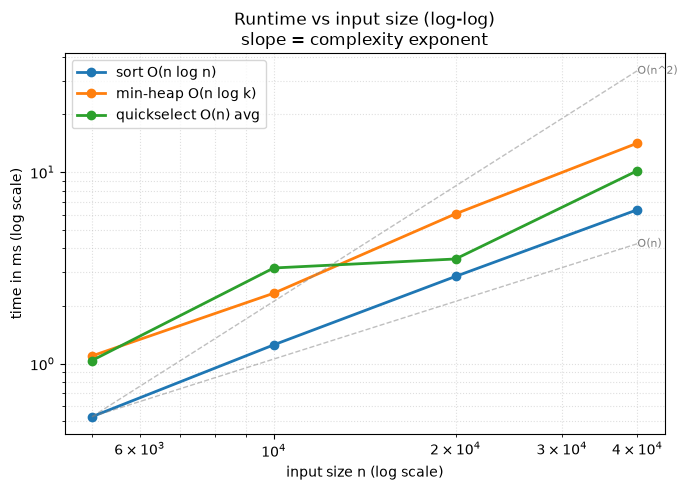

{'sort O(n log n)': [0.5283750360831618,
  1.2532080290839076,
  2.8529580449685454,
  6.358957965858281],
 'min-heap O(n log k)': [1.0971250012516975,
  2.3307909723371267,
  6.052208016626537,
  14.15412500500679],
 'quickselect O(n) avg': [1.0377499274909496,
  3.157124971039593,
  3.5179159604012966,
  10.163999977521598]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark


def make_worst_case(n):
    rng = random.Random(n)
    nums = [rng.randint(-10**4, 10**4) for _ in range(n)]
    return (nums, n // 2)                   # k = n/2: largest heap, deepest quickselect target

solutions = {
    "sort O(n log n)": find_kth_largest_sort,
    "min-heap O(n log k)": find_kth_largest_heap,
    "quickselect O(n) avg": find_kth_largest_quickselect,
}
sizes = [5000, 10000, 20000, 40000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Top K](README.md) — the size-k min-heap from Kth Largest in a Stream, run once over a fixed array; quickselect is the alternative when you may reorder the array and want `O(n)` average.
- **Heap vs quickselect:** the heap is `O(n log k)` time, `O(k)` space, and works on a stream; quickselect is `O(n)` average but needs the whole array in memory and a good (random) pivot.
- **3-way partition** settles all copies of the pivot at once, so arrays full of duplicates stay fast.
- **"k-th largest" = index `n - k` ascending** — convert once, then think in ascending order.
- **Signal:** "k-th largest / smallest", "top k", "can you do it without sorting?", "median" (k = n/2).
- **Related problems:** Kth Largest Element in a Stream, K Closest Points to Origin, Top K Frequent Elements, Find Median from Data Stream.
- **Common pitfalls:**
  1. Off-by-one between "k-th largest" and index `k`: the target is `n - k` in ascending order (or `k - 1` in descending).
  2. A fixed pivot (first or last element) on sorted input → `O(n²)`. Pick it at random.
  3. A 2-way partition with many equal values can degrade to `O(n²)`; the 3-way split avoids it.
  4. Treating duplicates as one value — they each count (Example 2).